# 11. Asymptotic complexity, measured

**Goal.** Check Big-O claims with data, find accidental quadratic code, and choose algorithms from evidence.

**You will be able to:**
1. Measure growth with `timeit` and fit an exponent from a log-log slope.
2. Compare the cost of common container operations at increasing sizes.
3. Compare sorting and searching algorithms across input shapes.
4. Read a plot and spot the constants that Big-O hides.

## 1. Measuring growth

### How it works under the hood
- Big-O describes how cost grows with input size n, ignoring constants. O(1) is flat, O(log n) grows slowly, O(n) doubles when n doubles, O(n log n) slightly more, O(n^2) quadruples.
- To measure, time a function at doubling sizes. On a log-log plot `time = c * n^k` becomes a straight line of slope `k`. A least-squares fit of `log(time)` against `log(n)` estimates `k`.
- `timeit` runs the code many times. The best of several repeats approximates the true cost, because noise only adds time.
- Small n hides growth: a fast constant can beat a better algorithm. Large n exposes it, until cache or memory limits add steps of their own.
- Amortised O(1) (list `append`) means the average over many calls, even though a rare call copies the whole array.

### Production use
- Load-test curves and capacity planning: if latency grows with slope 2, doubling traffic quadruples cost.
- Finding accidental quadratic code in reviews: `x in some_list` inside a loop, `str +=` in a loop, repeated `list.insert(0, ...)`.

### Trade-offs

| Method | Memory | Latency | Readability | Advantages | Disadvantages |
|---|---|---|---|---|---|
| Empirical fit (`timeit` and log-log slope) | Small tables | Seconds to run | Direct evidence | Tests real code and real hardware | Noisy, limited to sizes you can run |
| Paper analysis | None | None | Needs algebra | Exact growth class | Misses constants and cache effects |
| Profiler (`cProfile`) | Event log | Overhead per call | Shows where time goes | Finds hot spots | Does not give growth classes |

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "understanding_python").is_dir())
sys.path.insert(0, str(ROOT / "src"))
print("python", sys.version.split()[0], "| package root", ROOT.name)

python 3.13.6 | package root understanding-python


In [2]:
import random
import timeit

from understanding_python import bench


def report(title, rows):
    k = bench.fit_exponent(rows)
    cells = " ".join(f"{t * 1e6:>10.2f}" for _, t in rows)
    print(f"{title:<34}{cells}   slope {k:4.2f}  {bench.classify(k)}")


sizes = [1_000, 2_000, 4_000, 8_000, 16_000, 32_000]
print(f"{'operation':<34}" + " ".join(f"{'n=' + str(n):>10}" for n in sizes) + "   (microseconds)")

report("sum(list)  O(n)", bench.scaling_table(sum, lambda n: list(range(n)), sizes, number=20))
report("list[n//2]  O(1)", bench.scaling_table(lambda xs: xs[len(xs) // 2], lambda n: list(range(n)), sizes, number=2000))
report("x in list (worst)  O(n)", bench.scaling_table(lambda xs: -1 in xs, lambda n: list(range(n)), sizes, number=50))
report("x in set  O(1)", bench.scaling_table(lambda s: -1 in s, lambda n: set(range(n)), sizes, number=2000))
report("sorted(random)  O(n log n)", bench.scaling_table(sorted, lambda n: random.Random(n).sample(range(n), n), sizes, number=5))


def keep_tail():
    return bench.scaling_table(lambda xs: [xs.pop(0) for _ in range(len(xs) // 2)], lambda n: list(range(n)), sizes[:5], number=1)


report("pop(0) n/2 times  O(n^2)", keep_tail())

operation                             n=1000     n=2000     n=4000     n=8000    n=16000    n=32000   (microseconds)
sum(list)  O(n)                         6.11      12.14      24.19      49.01      96.16     191.76   slope 1.00  O(n) or O(n log n)
list[n//2]  O(1)                        0.16       0.16       0.16       0.16       0.16       0.16   slope 0.00  O(1) or O(log n)
x in list (worst)  O(n)                 8.84      17.72      35.39      71.56     141.46     287.47   slope 1.00  O(n) or O(n log n)
x in set  O(1)                          0.10       0.10       0.10       0.10       0.10       0.10   slope -0.00  O(1) or O(log n)


sorted(random)  O(n log n)             75.24     190.70     454.66    1010.94    2231.16    4988.16   slope 1.20  O(n) or O(n log n)
pop(0) n/2 times  O(n^2)               14.90      37.50     111.30     360.70    1314.10   slope 1.62  between O(n log n) and O(n^2)


## 2. Container operations at scale

### How it works under the hood
- `x in list` scans pointers and compares objects until a match: O(n). `x in set` hashes `x` and probes: O(1) average.
- `bisect` on a sorted list halves the range each step: O(log n). Sorting once and then bisecting beats repeated scans when you query many times.
- `sorted` uses Timsort: it finds natural runs and merges them. Sorted or nearly sorted input costs O(n).
- `str += piece` in a loop can copy the string each time, so cost grows with the square of the length.
- CPython sometimes optimises this in place, but `"".join(parts)` is always linear.
- Python integers and floats are objects. Pure Python loops cost tens of nanoseconds per step. Built-ins like `sum` and `sorted` run the loop in C.

### Production use
- Replace `if user_id in allowed_list` with a `set` built once.
- Build strings with `join`. Build large results with comprehensions. Use `deque` for FIFO queues.
- Sort once, then use `bisect` for repeated range queries.

### Trade-offs

| Choice | Memory | Latency | Readability | Advantages | Disadvantages |
|---|---|---|---|---|---|
| `set` for membership | About 3 to 4 times a list | O(1) | Same code | Constant-time tests | Build cost, unordered, hashable items only |
| Sorted list + `bisect` | Same as list | O(log n) query, O(n) insert | A few lines | Ordered queries, no extra memory | Slow updates |
| Linear scan | Lowest | O(n) | Simplest | No set-up | Slow when repeated |
| `join` vs `+=` | Temporary list | O(n) vs possibly O(n^2) | `join` is idiomatic | Predictable | Needs a list of parts |

strategy                     n=500    n=1000    n=2000    n=4000    n=8000  slope
scan a list per query        0.877     1.764     3.531     7.079    14.185  1.00   (ms for 200 queries)
set lookup per query         0.013     0.015     0.016     0.016     0.014  0.04   (ms for 200 queries)
bisect per query             0.033     0.034     0.037     0.040     0.041  0.09   (ms for 200 queries)


string building with s += piece          1.89     3.76     7.55    15.12    43.03 ms
string building with ''.join(parts)      1.14     2.22     4.46    10.12    19.87 ms


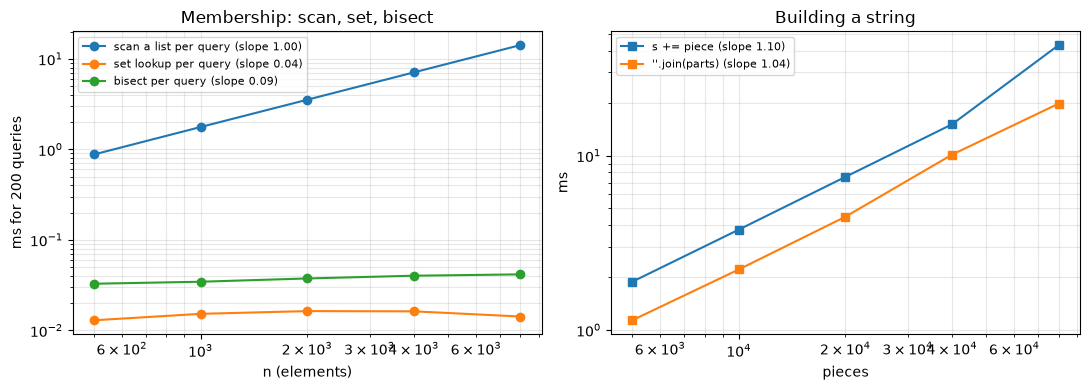

In [3]:
import bisect
import matplotlib.pyplot as plt

queries = [-(i + 1) for i in range(200)]  # absent keys: the worst case for a scan
ns = [500, 1_000, 2_000, 4_000, 8_000]
series = {
    "scan a list per query": lambda n: bench.best_time(lambda: [q in data_list[n] for q in queries], repeat=3),
    "set lookup per query": lambda n: bench.best_time(lambda: [q in data_set[n] for q in queries], repeat=3),
    "bisect per query": lambda n: bench.best_time(lambda: [bisect.bisect_left(data_list[n], q) for q in queries], repeat=3),
}
data_list = {n: list(range(n)) for n in ns}
data_set = {n: set(range(n)) for n in ns}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
print(f"{'strategy':<24}" + "".join(f"{'n=' + str(n):>10}" for n in ns) + "  slope")
for name, timing in series.items():
    rows = [(n, timing(n)) for n in ns]
    axes[0].loglog([n for n, _ in rows], [t * 1e3 for _, t in rows], marker="o", label=f"{name} (slope {bench.fit_exponent(rows):.2f})")
    print(f"{name:<24}" + "".join(f"{t * 1e3:>10.3f}" for _, t in rows) + f"  {bench.fit_exponent(rows):.2f}   (ms for 200 queries)")
axes[0].set_xlabel("n (elements)")
axes[0].set_ylabel("ms for 200 queries")
axes[0].set_title("Membership: scan, set, bisect")
axes[0].legend(fontsize=8)
axes[0].grid(True, which="both", alpha=0.3)


def concat_plus(n):
    s = ""
    for i in range(n):
        s += "log line %d\n" % i
    return s


def concat_join(n):
    return "".join("log line %d\n" % i for i in range(n))


for name, fn in (("s += piece", concat_plus), ("''.join(parts)", concat_join)):
    rows = [(n, bench.best_time(lambda: fn(n), repeat=3)) for n in (5_000, 10_000, 20_000, 40_000, 80_000)]
    axes[1].loglog([n for n, _ in rows], [t * 1e3 for _, t in rows], marker="s", label=f"{name} (slope {bench.fit_exponent(rows):.2f})")
    print(f"string building with {name:<16}" + " ".join(f"{t * 1e3:8.2f}" for _, t in rows) + " ms")
axes[1].set_xlabel("pieces")
axes[1].set_ylabel("ms")
axes[1].set_title("Building a string")
axes[1].legend(fontsize=8)
axes[1].grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Sorting and searching compared

### How it works under the hood
- **Insertion sort** grows a sorted prefix by shifting larger items right: O(n^2) worst case, O(n) when already sorted.
- **Merge sort** splits, sorts halves and merges: O(n log n) always, O(n) extra memory, stable.
- **Quicksort** partitions around a pivot: O(n log n) on average, O(n^2) with bad pivots. A random pivot makes the worst case unlikely.
- **Heap sort** builds a heap and pops it: O(n log n) always, in place, not stable, poor cache behaviour.
- **Counting sort** counts occurrences of small integer keys: O(n + k), no comparisons.
- Any comparison sort needs at least log2(n!) comparisons, about n log2 n, because it must distinguish n! orderings with yes/no answers.
- `sorted` is Timsort in C: merge sort plus insertion sort on small runs, adaptive on partly ordered data.

### Production use
- Use `sorted` or `list.sort` by default, with `key=` for records.
- Counting or radix sorts for bounded integer keys (ages, ratings, byte values).
- Merge sort ideas for external sorting of files larger than memory.
- Binary search on sorted arrays, and on the answer itself ("smallest capacity that ships all parcels in D days").

### Trade-offs

| Algorithm | Memory | Latency | Readability | Advantages | Disadvantages |
|---|---|---|---|---|---|
| Insertion sort | O(1) | O(n^2), O(n) if nearly sorted | Very short | Great for tiny or almost sorted input | Quadratic otherwise |
| Merge sort | O(n) | O(n log n) | Moderate | Stable, predictable | Extra memory |
| Quicksort | O(log n) stack | O(n log n) average | Moderate | Fast in practice | Bad pivots give O(n^2), not stable |
| Heap sort | O(1) | O(n log n) | Moderate | In place, no bad case | Slower constants |
| Counting sort | O(n + k) | O(n + k) | Short | Beats comparison bound | Needs small integer keys |
| `sorted` (Timsort) | O(n) | O(n log n), O(n) on runs | One call | C speed, adaptive, stable | Cannot be customised internally |

n = 2000; milliseconds, best of 3
                  random        sorted      reversed  few distinct


insertion         148.03          0.31        280.80        120.30
merge               5.18          3.51          3.72          5.08
quick               4.18          3.05          3.13          3.51


heap                5.94          6.22          5.58          5.58
sorted()            0.20          0.02          0.02          0.13
counting sort on 'few distinct': 0.15 ms

     n   merge sort comparisons   n log2 n   log2(n!) lower bound
    64                      306        384                    295
   256                    1,728      2,048                  1,683
  1024                    8,958     10,240                  8,769
  4096                   43,975     49,152                 43,250



insertion  fitted slope 2.03 -> about O(n^2) or worse
merge      fitted slope 1.13 -> O(n) or O(n log n)
sorted()   fitted slope 1.20 -> O(n) or O(n log n)


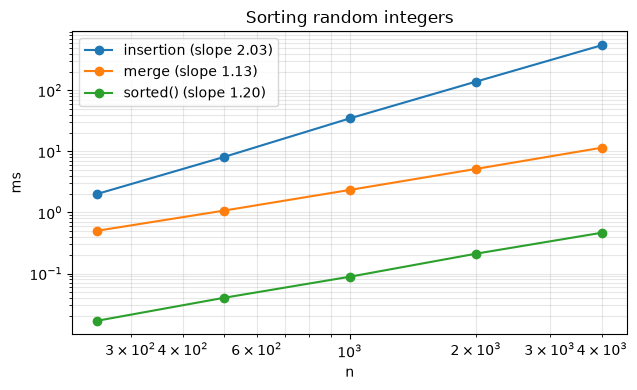

find the last of 1,000,000 items: linear 10.90 ms | own binary search 3.4 us | bisect 0.28 us
search on the answer: smallest x with x*x >= 1_000_000_007 -> 31623


In [4]:
import math
import random

from understanding_python import algorithms as al

rng = random.Random(2026)
n = 2000
shapes = {
    "random": [rng.randint(0, 10**6) for _ in range(n)],
    "sorted": list(range(n)),
    "reversed": list(range(n, 0, -1)),
    "few distinct": [rng.randint(0, 9) for _ in range(n)],
}
sorters = {
    "insertion": al.insertion_sort,
    "merge": al.merge_sort,
    "quick": al.quick_sort,
    "heap": al.heap_sort,
    "sorted()": sorted,
}
print(f"n = {n}; milliseconds, best of 3")
print(f"{'':<10}" + "".join(f"{s:>14}" for s in shapes))
for name, fn in sorters.items():
    cells = []
    for data in shapes.values():
        assert fn(list(data)) == sorted(data)
        cells.append(bench.best_time(lambda: fn(list(data)), repeat=3) * 1e3)
    print(f"{name:<10}" + "".join(f"{c:>14.2f}" for c in cells))
print("counting sort on 'few distinct':", f"{bench.best_time(lambda: al.counting_sort(shapes['few distinct'], 10), repeat=3) * 1e3:.2f} ms")

print(f"\n{'n':>6} {'merge sort comparisons':>24} {'n log2 n':>10} {'log2(n!) lower bound':>22}")
for size in (64, 256, 1024, 4096):
    data = rng.sample(range(10**6), size)
    print(f"{size:>6} {al.count_comparisons(al.merge_sort, data):>24,} {int(size * math.log2(size)):>10,} {int(math.lgamma(size + 1) / math.log(2)):>22,}")

sort_sizes = [250, 500, 1000, 2000, 4000]
fig, ax = plt.subplots(figsize=(6.5, 4))
print()
for name, fn in (("insertion", al.insertion_sort), ("merge", al.merge_sort), ("sorted()", sorted)):
    rows = bench.scaling_table(lambda xs: fn(list(xs)), lambda m: [rng.randint(0, 10**6) for _ in range(m)], sort_sizes, repeat=2)
    k = bench.fit_exponent(rows)
    ax.loglog([m for m, _ in rows], [t * 1e3 for _, t in rows], marker="o", label=f"{name} (slope {k:.2f})")
    print(f"{name:<10} fitted slope {k:.2f} -> {bench.classify(k)}")
ax.set_xlabel("n")
ax.set_ylabel("ms")
ax.set_title("Sorting random integers")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

big = list(range(0, 2_000_000, 2))
target = 1_999_998
t_lin = bench.best_time(lambda: big.index(target), repeat=3)
t_bin = bench.best_time(lambda: al.binary_search(big, target), repeat=3, number=100)
t_std = bench.best_time(lambda: bisect.bisect_left(big, target), repeat=3, number=100)
print(f"find the last of 1,000,000 items: linear {t_lin * 1e3:.2f} ms | own binary search {t_bin * 1e6:.1f} us | bisect {t_std * 1e6:.2f} us")
print("search on the answer: smallest x with x*x >= 1_000_000_007 ->", al.search_on_answer(lambda x: x * x >= 1_000_000_007, 0, 10**6))